In [8]:

import duckdb
import pandas as pd

# Public AMR Portal phenotype dataset
url = (
    "https://ftp.ebi.ac.uk/pub/databases/amr_portal/"
    "releases/2026-07/phenotype.parquet"
)

query = """
SELECT
    species,
    antibiotic_name,
    COUNT(*) AS records,
    COUNT(DISTINCT BioSample_ID) AS unique_samples,
    COUNT(DISTINCT CASE
        WHEN assembly_ID IS NOT NULL AND assembly_ID != ''
        THEN BioSample_ID
    END) AS samples_with_assembly,
    COUNT(DISTINCT CASE
        WHEN LOWER(resistance_phenotype) = 'resistant'
        THEN BioSample_ID
    END) AS resistant_samples,
    COUNT(DISTINCT CASE
        WHEN LOWER(resistance_phenotype) = 'susceptible'
        THEN BioSample_ID
    END) AS susceptible_samples
FROM read_parquet(?)
WHERE
    resistance_phenotype IS NOT NULL
    AND antibiotic_name IS NOT NULL
    AND species IS NOT NULL
GROUP BY species, antibiotic_name
HAVING COUNT(DISTINCT BioSample_ID) >= 100
ORDER BY samples_with_assembly DESC, unique_samples DESC
LIMIT 30
"""

results = duckdb.execute(query, [url]).df()

display(results)


,species,antibiotic_name,records,unique_samples,samples_with_assembly,resistant_samples,susceptible_samples
0,Salmonella enterica,chloramphenicol,28100,28058,23870,2928,24867
1,Salmonella enterica,ciprofloxacin,27818,27790,23811,2247,22540
2,Salmonella enterica,ampicillin,28021,28012,23810,5724,22257
3,Salmonella enterica,tetracycline,26498,26492,23655,6964,19417
4,Salmonella enterica,gentamicin,26217,26167,23312,1128,24623
5,Salmonella enterica,trimethoprim-sulfamethoxazole,26694,26673,23131,1679,25004
6,Salmonella enterica,amoxicillin-clavulanic acid,25017,24925,22602,1473,22654
7,Salmonella enterica,azithromycin,24968,24938,22519,315,24622
8,Salmonella enterica,nalidixic acid,24635,24630,21243,3816,20508
9,Salmonella enterica,streptomycin,23372,23360,21213,5390,17919


In [9]:

query_matched = """
WITH source_rows AS (
    SELECT
        species,
        antibiotic_name,
        BioSample_ID,
        assembly_ID,
        LOWER(TRIM(resistance_phenotype)) AS phenotype
    FROM read_parquet(?)
    WHERE
        species IS NOT NULL
        AND antibiotic_name IS NOT NULL
        AND BioSample_ID IS NOT NULL
        AND assembly_ID IS NOT NULL
        AND TRIM(assembly_ID) != ''
        AND LOWER(TRIM(resistance_phenotype))
            IN ('resistant', 'susceptible')
),
sample_labels AS (
    SELECT
        species,
        antibiotic_name,
        BioSample_ID,
        MAX(CASE WHEN phenotype = 'resistant'
                 THEN 1 ELSE 0 END) AS has_resistant,
        MAX(CASE WHEN phenotype = 'susceptible'
                 THEN 1 ELSE 0 END) AS has_susceptible,
        COUNT(DISTINCT assembly_ID) AS assembly_count
    FROM source_rows
    GROUP BY species, antibiotic_name, BioSample_ID
),
clean_samples AS (
    SELECT *
    FROM sample_labels
    WHERE has_resistant + has_susceptible = 1
)
SELECT
    species,
    antibiotic_name,
    COUNT(*) AS eligible_samples,
    SUM(has_resistant) AS resistant_samples,
    SUM(has_susceptible) AS susceptible_samples,
    SUM(CASE WHEN assembly_count > 1
             THEN 1 ELSE 0 END) AS samples_with_multiple_assemblies
FROM clean_samples
GROUP BY species, antibiotic_name
HAVING
    SUM(has_resistant) >= 500
    AND SUM(has_susceptible) >= 500
ORDER BY
    LEAST(SUM(has_resistant), SUM(has_susceptible)) DESC
LIMIT 20
"""

matched_results = duckdb.execute(
    query_matched, [url]
).df()

display(matched_results)


,species,antibiotic_name,eligible_samples,resistant_samples,susceptible_samples,samples_with_multiple_assemblies
0,Salmonella enterica,tetracycline,23553,6297.0,17256.0,0.0
1,Escherichia coli,ampicillin,10774,5278.0,5496.0,0.0
2,Salmonella enterica,streptomycin,21176,4948.0,16228.0,0.0
3,Salmonella enterica,ampicillin,23785,4494.0,19291.0,0.0
4,Streptococcus pneumoniae,trimethoprim-sulfamethoxazole,10486,4482.0,6004.0,0.0
5,Salmonella enterica,sulfisoxazole,19704,3542.0,16162.0,0.0
6,Escherichia coli,tetracycline,8172,3291.0,4881.0,0.0
7,Salmonella enterica,nalidixic acid,21239,3238.0,18001.0,0.0
8,Campylobacter jejuni,tetracycline,5858,2597.0,3261.0,0.0
9,Neisseria gonorrhoeae,ciprofloxacin,5612,2511.0,3101.0,0.0


In [10]:

import duckdb
import pandas as pd

base_url = "https://ftp.ebi.ac.uk/pub/databases/amr_portal/releases/2026-07/"

phenotype_url = base_url + "phenotype.parquet"
genotype_url = base_url + "genotype.parquet"

# First, inspect the available genomic feature columns.
genotype_schema = duckdb.execute(
    "DESCRIBE SELECT * FROM read_parquet(?)",
    [genotype_url]
).df()

display(genotype_schema[["column_name", "column_type"]])

# Next, check how many labelled samples have genomic annotations.
query = """
WITH source_rows AS (
    SELECT
        BioSample_ID,
        assembly_ID,
        LOWER(TRIM(resistance_phenotype)) AS phenotype
    FROM read_parquet(?)
    WHERE LOWER(TRIM(species)) = 'escherichia coli'
      AND LOWER(TRIM(antibiotic_name)) = 'ampicillin'
      AND assembly_ID IS NOT NULL
      AND TRIM(assembly_ID) != ''
      AND LOWER(TRIM(resistance_phenotype))
          IN ('resistant', 'susceptible')
),
labels AS (
    SELECT
        BioSample_ID,
        assembly_ID,
        MAX(CASE WHEN phenotype = 'resistant'
                 THEN 1 ELSE 0 END) AS has_resistant,
        MAX(CASE WHEN phenotype = 'susceptible'
                 THEN 1 ELSE 0 END) AS has_susceptible
    FROM source_rows
    GROUP BY BioSample_ID, assembly_ID
),
clean_labels AS (
    SELECT *
    FROM labels
    WHERE has_resistant + has_susceptible = 1
),
genome_pairs AS (
    SELECT DISTINCT BioSample_ID, assembly_ID
    FROM read_parquet(?)
    WHERE LOWER(TRIM(species)) = 'escherichia coli'
)
SELECT
    COUNT(*) AS labelled_samples,
    SUM(CASE WHEN g.BioSample_ID IS NOT NULL
             THEN 1 ELSE 0 END) AS samples_with_genotype_records,
    SUM(CASE WHEN g.BioSample_ID IS NULL
             THEN 1 ELSE 0 END) AS samples_without_genotype_records
FROM clean_labels AS l
LEFT JOIN genome_pairs AS g
    ON l.BioSample_ID = g.BioSample_ID
   AND l.assembly_ID = g.assembly_ID
"""

feature_check = duckdb.execute(
    query, [phenotype_url, genotype_url]
).df()

display(feature_check)


,column_name,column_type
0,BioSample_ID,VARCHAR
1,assembly_ID,VARCHAR
2,genus,VARCHAR
3,species,VARCHAR
4,organism,VARCHAR
5,isolate,VARCHAR
6,taxon_id,BIGINT
7,region,VARCHAR
8,region_start,BIGINT
9,region_end,BIGINT


,labelled_samples,samples_with_genotype_records,samples_without_genotype_records
0,10774,10573.0,201.0


In [11]:


base_url = (
    "https://ftp.ebi.ac.uk/pub/databases/amr_portal/"
    "releases/2026-07/"
)
genotype_url = base_url + "genotype.parquet"

# Inspect the most common annotation types and resistance classes.
query = """
SELECT
    element_type,
    class,
    subclass,
    COUNT(*) AS annotation_records,
    COUNT(DISTINCT BioSample_ID) AS unique_samples,
    COUNT(DISTINCT gene_symbol) AS unique_gene_symbols
FROM read_parquet(?)
WHERE LOWER(TRIM(species)) = 'escherichia coli'
GROUP BY element_type, class, subclass
ORDER BY annotation_records DESC
LIMIT 25
"""

annotation_summary = duckdb.execute(
    query, [genotype_url]
).df()

display(annotation_summary)


,element_type,class,subclass,annotation_records,unique_samples,unique_gene_symbols
0,AMR,BETA-LACTAM,BETA-LACTAM,43881,21739,56
1,AMR,EFFLUX,EFFLUX,39848,23470,14
2,AMR,AMINOGLYCOSIDE,STREPTOMYCIN,24621,8155,27
3,AMR,MACROLIDE,AZITHROMYCIN/ERYTHROMYCIN/SPIRAMYCIN/TELITHROM...,22004,3755,0
4,AMR,QUINOLONE,QUINOLONE,20008,8994,22
5,AMR,SULFONAMIDE,SULFONAMIDE,19278,9435,14
6,AMR,MULTIDRUG,AMPICILLIN/CHLORAMPHENICOL/QUINOLONE/RIFAMPIN/...,16115,3223,6
7,AMR,TETRACYCLINE,TETRACYCLINE,14664,8812,19
8,AMR,BETA-LACTAM,CEPHALOSPORIN,14135,8543,23
9,AMR,TRIMETHOPRIM,TRIMETHOPRIM,9993,6702,17


In [12]:

quality_query = """
SELECT
    COUNT(*) AS annotation_rows,
    COUNT(DISTINCT BioSample_ID) AS samples,
    COUNT(DISTINCT amr_element_symbol) AS unique_amr_elements,
    COUNT(DISTINCT gene_symbol) AS unique_gene_symbols,
    SUM(CASE WHEN amr_element_symbol IS NULL
                  OR TRIM(amr_element_symbol) = ''
             THEN 1 ELSE 0 END) AS missing_amr_element,
    SUM(CASE WHEN gene_symbol IS NULL
                  OR TRIM(gene_symbol) = ''
             THEN 1 ELSE 0 END) AS missing_gene_symbol
FROM read_parquet(?)
WHERE LOWER(TRIM(species)) = 'escherichia coli'
"""

quality = duckdb.execute(
    quality_query, [genotype_url]
).df()

display(quality)

# Inspect example annotation markers.
examples_query = """
SELECT
    amr_element_symbol,
    gene_symbol,
    element_type,
    class,
    subclass
FROM read_parquet(?)
WHERE LOWER(TRIM(species)) = 'escherichia coli'
LIMIT 15
"""

examples = duckdb.execute(
    examples_query, [genotype_url]
).df()

display(examples)


,annotation_rows,samples,unique_amr_elements,unique_gene_symbols,missing_amr_element,missing_gene_symbol
0,261295,23544,454,397,0.0,37087.0


,amr_element_symbol,gene_symbol,element_type,class,subclass
0,aph(3')-Ia,neo,AMR,AMINOGLYCOSIDE,KANAMYCIN
1,tet(A),tetA,AMR,TETRACYCLINE,TETRACYCLINE
2,dfrA5,dhfrI,AMR,TRIMETHOPRIM,TRIMETHOPRIM
3,blaEC,ampC,AMR,BETA-LACTAM,BETA-LACTAM
4,dfrA51,dfrD,AMR,TRIMETHOPRIM,TRIMETHOPRIM
5,acrF,acrF,AMR,EFFLUX,EFFLUX
6,blaCTX-M-1,bla,AMR,BETA-LACTAM,CEPHALOSPORIN
7,fosA7,fosA,AMR,FOSFOMYCIN,FOSFOMYCIN
8,mdtM,mdtM,AMR,EFFLUX,EFFLUX
9,cyaA_S352T,cyaA,AMR,FOSMIDOMYCIN,FOSMIDOMYCIN


In [13]:

# Inspect the columns available for linking annotations to samples.
schema_query = """
DESCRIBE SELECT *
FROM read_parquet(?)
"""

genotype_columns = duckdb.execute(
    schema_query, [genotype_url]
).df()

display(genotype_columns[["column_name", "column_type"]])


,column_name,column_type
0,BioSample_ID,VARCHAR
1,assembly_ID,VARCHAR
2,genus,VARCHAR
3,species,VARCHAR
4,organism,VARCHAR
5,isolate,VARCHAR
6,taxon_id,BIGINT
7,region,VARCHAR
8,region_start,BIGINT
9,region_end,BIGINT


In [14]:

import duckdb
import pandas as pd

base_url = (
    "https://ftp.ebi.ac.uk/pub/databases/amr_portal/"
    "releases/2026-07/"
)
phenotype_url = base_url + "phenotype.parquet"
genotype_url = base_url + "genotype.parquet"

# 1. Obtain unambiguous phenotype labels.
label_query = """
WITH records AS (
    SELECT DISTINCT
        BioSample_ID,
        assembly_ID,
        LOWER(TRIM(resistance_phenotype)) AS phenotype
    FROM read_parquet(?)
    WHERE LOWER(TRIM(species)) = 'escherichia coli'
      AND LOWER(TRIM(antibiotic_name)) = 'ampicillin'
      AND assembly_ID IS NOT NULL
      AND TRIM(assembly_ID) != ''
      AND LOWER(TRIM(resistance_phenotype))
          IN ('resistant', 'susceptible')
),
grouped AS (
    SELECT
        BioSample_ID,
        assembly_ID,
        COUNT(DISTINCT phenotype) AS label_count,
        MAX(CASE WHEN phenotype = 'resistant'
                 THEN 1 ELSE 0 END) AS resistant
    FROM records
    GROUP BY BioSample_ID, assembly_ID
)
SELECT BioSample_ID, assembly_ID, resistant AS target
FROM grouped
WHERE label_count = 1
"""

labels = duckdb.execute(
    label_query, [phenotype_url]
).df()

print("Unambiguous labelled samples:", len(labels))
print(labels["target"].value_counts().rename(
    index={0: "Susceptible", 1: "Resistant"}
))

# 2. Load genomic markers for E. coli.
marker_query = """
SELECT DISTINCT
    BioSample_ID,
    assembly_ID,
    TRIM(amr_element_symbol) AS marker
FROM read_parquet(?)
WHERE LOWER(TRIM(species)) = 'escherichia coli'
  AND amr_element_symbol IS NOT NULL
  AND TRIM(amr_element_symbol) != ''
"""

markers = duckdb.execute(
    marker_query, [genotype_url]
).df()

# 3. Keep only markers linked to our labelled assemblies.
matched = markers.merge(
    labels[["BioSample_ID", "assembly_ID"]],
    on=["BioSample_ID", "assembly_ID"],
    how="inner",
    validate="many_to_one"
)

# One binary feature per marker; 1 means detected in the annotations.
X = pd.crosstab(
    index=[matched["BioSample_ID"], matched["assembly_ID"]],
    columns=matched["marker"]
)
X = (X > 0).astype("int8")
X.columns = [f"marker_{c}" for c in X.columns]
X.index.names = ["BioSample_ID", "assembly_ID"]

# 4. Attach the target labels.
y = labels.set_index(
    ["BioSample_ID", "assembly_ID"]
)["target"]

common_ids = X.index.intersection(y.index)
X = X.loc[common_ids].sort_index()
y = y.loc[common_ids].sort_index()

print("\nFeature matrix shape:", X.shape)
print("Label vector shape:", y.shape)
print("Unique assemblies:", X.index.get_level_values(
    "assembly_ID"
).nunique())
print("Class distribution:")
print(y.value_counts().rename(
    index={0: "Susceptible", 1: "Resistant"}
))

display(X.head())


Unambiguous labelled samples: 10774
target
Susceptible    5496
Resistant      5278
Name: count, dtype: int64

Feature matrix shape: (10573, 321)
Label vector shape: (10573,)
Unique assemblies: 10573
Class distribution:
target
Susceptible    5420
Resistant      5153
Name: count, dtype: int64


,,marker_aac(2')-IIa,marker_aac(3),marker_aac(3)-II,marker_aac(3)-IId,marker_aac(3)-IIe,marker_aac(3)-IIg,marker_aac(3)-IVa,marker_aac(3)-Ia,marker_aac(3)-VIa,marker_aac(6'),...,marker_tet(B),marker_tet(C),marker_tet(D),marker_tet(E),marker_tet(H),marker_tet(M),marker_tet(X4),marker_tet(X5),marker_uhpT_E350Q,marker_vanZ-A
BioSample_ID,assembly_ID,,,,,,,,,,,,,,,,,,,,,
SAMD00126358,GCA_003297305.1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
SAMD00126359,GCA_003297345.1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
SAMD00126360,GCA_003297365.1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
SAMD00126361,GCA_003297405.1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
SAMD00126362,GCA_003297455.1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Training samples: 8458
Testing samples: 2115

MODEL PERFORMANCE
----------------------------------------
Accuracy:  0.9447
Precision: 0.9800
Recall:    0.9049
F1-score:  0.9410
ROC-AUC:   0.9656

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Susceptible       0.92      0.98      0.95      1084
   Resistant       0.98      0.90      0.94      1031

    accuracy                           0.94      2115
   macro avg       0.95      0.94      0.94      2115
weighted avg       0.95      0.94      0.94      2115



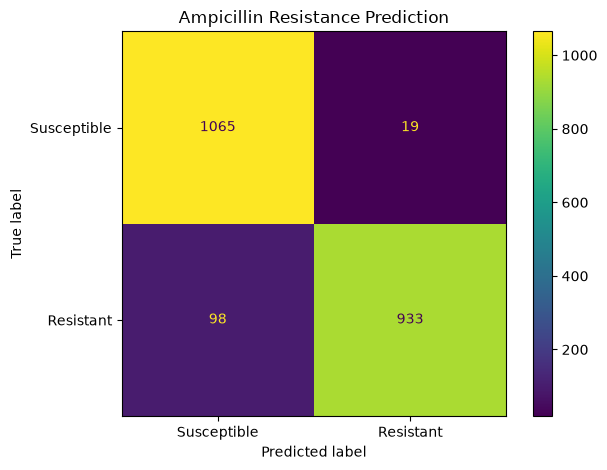


FALSE POSITIVES: 19


,,Actual,Predicted,Predicted_Resistance_Probability
BioSample_ID,assembly_ID,,,
SAMN37300944,GCA_032300135.1,Susceptible,Resistant,0.999365
SAMN36729104,GCA_032331075.2,Susceptible,Resistant,0.945479
SAMN43563889,GCA_044689385.1,Susceptible,Resistant,0.985347
SAMN26308767,GCA_023880165.1,Susceptible,Resistant,0.558485
SAMN26304623,GCA_023878265.1,Susceptible,Resistant,0.558485



FALSE NEGATIVES: 98


,,Actual,Predicted,Predicted_Resistance_Probability
BioSample_ID,assembly_ID,,,
SAMN02801972,GCA_000780215.1,Resistant,Susceptible,0.078354
SAMN43563614,GCA_044079145.1,Resistant,Susceptible,0.075632
SAMN04357680,GCA_012670405.1,Resistant,Susceptible,0.041833
SAMN43563897,GCA_044689485.1,Resistant,Susceptible,0.147625
SAMN13024110,GCA_012859285.1,Resistant,Susceptible,0.078354


In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Split real samples into training and testing sets.
# Stratification keeps the resistant/susceptible proportions similar.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# 2. Train the classification model.
model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

# 3. Predict labels and resistance probabilities on unseen test samples.
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 4. Evaluate performance.
print("\nMODEL PERFORMANCE")
print("-" * 40)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Susceptible", "Resistant"],
    zero_division=0
))

# 5. Confusion matrix.
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Susceptible", "Resistant"]
)
display_matrix.plot(values_format="d")
plt.title("Ampicillin Resistance Prediction")
plt.tight_layout()
plt.show()

# 6. Find false positives and false negatives.
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred,
    "Predicted_Resistance_Probability": y_prob
}, index=y_test.index)

results["Actual"] = results["Actual"].map({
    0: "Susceptible",
    1: "Resistant"
})
results["Predicted"] = results["Predicted"].map({
    0: "Susceptible",
    1: "Resistant"
})

false_positives = results[
    (results["Actual"] == "Susceptible") &
    (results["Predicted"] == "Resistant")
]

false_negatives = results[
    (results["Actual"] == "Resistant") &
    (results["Predicted"] == "Susceptible")
]

print("\nFALSE POSITIVES:", len(false_positives))
display(false_positives.head(5))

print("\nFALSE NEGATIVES:", len(false_negatives))
display(false_negatives.head(5))


In [18]:

# ERROR ANALYSIS: Which markers appear in misclassified samples?

# 1. Identify false positives and false negatives.
fp_index = results.index[
    (results["Actual"] == "Susceptible") &
    (results["Predicted"] == "Resistant")
]

fn_index = results.index[
    (results["Actual"] == "Resistant") &
    (results["Predicted"] == "Susceptible")
]

# 2. Helper function: list markers detected in each sample.
def show_detected_markers(sample_index, title, max_samples=5):
    print(f"\n{title}")
    print("=" * len(title))

    for sample_id in list(sample_index[:max_samples]):
        sample_features = X.loc[sample_id]
        detected = sample_features[sample_features == 1].index.tolist()

        # Remove the "marker_" prefix for readability.
        detected = [
            name.removeprefix("marker_")
            for name in detected
        ]

        print(f"\nBioSample: {sample_id[0]}")
        print(f"Assembly:  {sample_id[1]}")
        print(f"Detected markers ({len(detected)}):")
        print(detected if detected else "No markers detected")

# 3. Inspect five examples of each error type.
show_detected_markers(
    fp_index,
    "FALSE POSITIVES: susceptible samples predicted resistant"
)

show_detected_markers(
    fn_index,
    "FALSE NEGATIVES: resistant samples predicted susceptible"
)

# 4. Which features most strongly influence the model?
coef = pd.Series(
    model.coef_[0],
    index=X.columns
).sort_values()

print("\nMarkers most associated with a RESISTANT prediction:")
display(
    coef.tail(15).sort_values(ascending=False).rename("Coefficient")
)

print("\nMarkers most associated with a SUSCEPTIBLE prediction:")
display(
    coef.head(15).rename("Coefficient")
)



FALSE POSITIVES: susceptible samples predicted resistant

BioSample: SAMN37300944
Assembly:  GCA_032300135.1
Detected markers (12):
['aadA1', 'acrF', 'blaCMY-2', 'blaEC', 'dfrA1', 'floR', 'mcr-1.1', 'mdtM', 'qnrS1', 'sat2', 'sul2', 'tet(B)']

BioSample: SAMN36729104
Assembly:  GCA_032331075.2
Detected markers (11):
['aadA5', 'acrF', 'blaCTX-M-15', 'blaEC', 'dfrA17', 'gyrA_S83L', 'mdtM', 'parC_S80I', 'parE_S458A', 'sul1', 'tet(B)']

BioSample: SAMN43563889
Assembly:  GCA_044689385.1
Detected markers (12):
['aac(3)-VIa', 'aadA1', 'aadA5', 'acrF', 'blaEC', 'blaTEM-1', 'cyaA_S352T', 'dfrA17', 'mdtM', 'sul1', 'sul2', 'uhpT_E350Q']

BioSample: SAMN26308767
Assembly:  GCA_023880165.1
Detected markers (16):
['aadA5', 'acrF', "aph(3'')-Ib", 'aph(6)-Id', 'blaEC', 'dfrA17', 'gyrA_S83L', 'mdtM', 'mph(A)', 'parC_S80I', 'parE_I529L', 'ptsI_V25I', 'sul1', 'sul2', 'tet(A)', 'uhpT_E350Q']

BioSample: SAMN26304623
Assembly:  GCA_023878265.1
Detected markers (16):
['aadA5', 'acrF', "aph(3'')-Ib", 'aph(6

marker_blaCMY-2       5.310474
marker_blaHER-3       5.193012
marker_blaTEM-1       5.171926
marker_blaCTX-M-1     5.134271
marker_blaOXA-48      4.056352
marker_blaSHV-1       3.769093
marker_blaCTX-M-55    3.379986
marker_blaCTX-M-15    3.313214
marker_blaCTX-M-32    3.251968
marker_blaSHV-2A      2.851345
marker_blaCTX-M-27    2.825944
marker_ere(A)         2.652022
marker_blaTEM-30      2.623671
marker_blaCTX-M-8     2.442091
marker_blaTEM-135     2.247771
Name: Coefficient, dtype: float64


Markers most associated with a SUSCEPTIBLE prediction:


marker_bleO           -0.953188
marker_parE_D475E     -0.874876
marker_folP_P64S      -0.776368
marker_parC_S80R      -0.769638
marker_blaOXA         -0.752051
marker_folP_F28L      -0.745195
marker_catA2          -0.587588
marker_parE_I355T     -0.576911
marker_dfrA27         -0.553930
marker_catB3          -0.550327
marker_pmrB_V161G     -0.493116
marker_parC_A56T      -0.416685
marker_blaCTX-M-174   -0.415960
marker_aph(4)-Ia      -0.406407
marker_dfrA15         -0.401277
Name: Coefficient, dtype: float64

In [19]:

# VALIDATION DIAGNOSTICS — do not modify the existing model

import pandas as pd
import numpy as np

# 1. Check whether sample identifiers are unique.
print("SAMPLE IDENTIFIER CHECK")
print("-" * 40)
print("Feature-matrix rows:", len(X))
print("Unique BioSample IDs:", X.index.get_level_values("BioSample_ID").nunique())
print("Unique assembly IDs:", X.index.get_level_values("assembly_ID").nunique())
print("Duplicate sample keys:", X.index.duplicated().sum())

# 2. Check for identical genomic-marker profiles.
# Samples with the same profile have the same 0/1 values for all features.
profile_hash = pd.util.hash_pandas_object(X, index=False)
profile_counts = profile_hash.value_counts()

duplicate_profile_rows = int(profile_hash.isin(
    profile_counts[profile_counts > 1].index
).sum())

print("\nMARKER PROFILE CHECK")
print("-" * 40)
print("Distinct marker profiles:", profile_hash.nunique())
print("Rows belonging to a repeated profile:", duplicate_profile_rows)
print("Repeated profiles beyond their first occurrence:",
      len(X) - profile_hash.nunique())

# 3. Check whether identical profiles have conflicting labels.
profile_labels = pd.DataFrame({
    "profile": profile_hash.to_numpy(),
    "target": y.to_numpy()
})
labels_per_profile = profile_labels.groupby("profile")["target"].nunique()

print("Profiles associated with both labels:",
      int((labels_per_profile > 1).sum()))

# 4. Check whether the target labels align with the feature matrix.
print("\nLABEL CHECK")
print("-" * 40)
print("X and y have identical indexes:", X.index.equals(y.index))
print("Missing labels:", int(y.isna().sum()))
print("Label distribution:")
print(y.value_counts().rename(index={0: "Susceptible", 1: "Resistant"}))


SAMPLE IDENTIFIER CHECK
----------------------------------------
Feature-matrix rows: 10573
Unique BioSample IDs: 10573
Unique assembly IDs: 10573
Duplicate sample keys: 0

MARKER PROFILE CHECK
----------------------------------------
Distinct marker profiles: 3563
Rows belonging to a repeated profile: 7887
Repeated profiles beyond their first occurrence: 7010
Profiles associated with both labels: 136

LABEL CHECK
----------------------------------------
X and y have identical indexes: True
Missing labels: 0
Label distribution:
target
Susceptible    5420
Resistant      5153
Name: count, dtype: int64


GROUP-AWARE SPLIT
----------------------------------------
Training samples: 8637
Testing samples: 1936
Training resistant proportion: 0.4772
Testing resistant proportion: 0.5325
Profiles shared between train and test: 0

GROUP-AWARE MODEL PERFORMANCE
----------------------------------------
Accuracy:  0.9303
Precision: 0.9619
Recall:    0.9049
F1-score:  0.9325
ROC-AUC:   0.9511

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Susceptible       0.90      0.96      0.93       905
   Resistant       0.96      0.90      0.93      1031

    accuracy                           0.93      1936
   macro avg       0.93      0.93      0.93      1936
weighted avg       0.93      0.93      0.93      1936



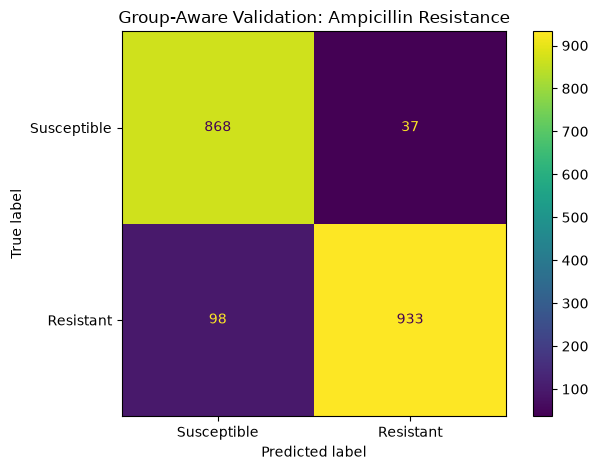

In [20]:

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Create five group-aware folds.
# Identical marker profiles must stay in the same fold.
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    cv.split(X, y, groups=profile_hash.to_numpy())
)

X_train_group = X.iloc[train_idx]
X_test_group = X.iloc[test_idx]
y_train_group = y.iloc[train_idx]
y_test_group = y.iloc[test_idx]

# 2. Verify that no exact marker profile crosses the split.
train_profiles = set(profile_hash.iloc[train_idx])
test_profiles = set(profile_hash.iloc[test_idx])

overlap = train_profiles.intersection(test_profiles)

print("GROUP-AWARE SPLIT")
print("-" * 40)
print("Training samples:", len(X_train_group))
print("Testing samples:", len(X_test_group))
print("Training resistant proportion:",
      round(y_train_group.mean(), 4))
print("Testing resistant proportion:",
      round(y_test_group.mean(), 4))
print("Profiles shared between train and test:", len(overlap))

# 3. Train a fresh model on the new training split.
group_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

group_model.fit(X_train_group, y_train_group)

# 4. Evaluate on samples whose marker profiles were held out.
y_pred_group = group_model.predict(X_test_group)
y_prob_group = group_model.predict_proba(X_test_group)[:, 1]

print("\nGROUP-AWARE MODEL PERFORMANCE")
print("-" * 40)
print(f"Accuracy:  {accuracy_score(y_test_group, y_pred_group):.4f}")
print(f"Precision: {precision_score(y_test_group, y_pred_group, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_group, y_pred_group, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test_group, y_pred_group, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_group, y_prob_group):.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_group,
    y_pred_group,
    labels=[0, 1],
    target_names=["Susceptible", "Resistant"],
    zero_division=0
))

# 5. Plot the new confusion matrix.
cm_group = confusion_matrix(
    y_test_group,
    y_pred_group,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_group,
    display_labels=["Susceptible", "Resistant"]
).plot(values_format="d")

plt.title("Group-Aware Validation: Ampicillin Resistance")
plt.tight_layout()
plt.show()


In [21]:

import pandas as pd
from sklearn.metrics import confusion_matrix

# 1. Create a results table for the group-aware test set.
error_results = pd.DataFrame(index=X_test_group.index)

error_results["Actual"] = y_test_group.map({
    0: "Susceptible",
    1: "Resistant"
})

error_results["Predicted"] = pd.Series(
    y_pred_group,
    index=X_test_group.index
).map({
    0: "Susceptible",
    1: "Resistant"
})

error_results["Resistance_Probability"] = y_prob_group

# 2. Identify false positives and false negatives.
false_positives = error_results[
    (error_results["Actual"] == "Susceptible") &
    (error_results["Predicted"] == "Resistant")
]

false_negatives = error_results[
    (error_results["Actual"] == "Resistant") &
    (error_results["Predicted"] == "Susceptible")
]

# 3. Print exact confusion-matrix counts.
cm = confusion_matrix(y_test_group, y_pred_group, labels=[0, 1])

print("CONFUSION MATRIX")
print("Rows = actual; columns = predicted")
print("                 Predicted Susceptible | Predicted Resistant")
print(f"Actual Susceptible: {cm[0, 0]:>10}       | {cm[0, 1]:>10}")
print(f"Actual Resistant:   {cm[1, 0]:>10}       | {cm[1, 1]:>10}")

print("\nFALSE POSITIVES:", len(false_positives))
print("FALSE NEGATIVES:", len(false_negatives))


# 4. Display example errors and their detected markers.
def show_error_examples(error_table, feature_matrix, title, limit=5):
    print(f"\n{title}")
    print("=" * 60)

    if error_table.empty:
        print("No errors of this type in the test set.")
        return

    for sample_id, row in error_table.head(limit).iterrows():
        detected_markers = feature_matrix.loc[sample_id]
        detected_markers = detected_markers[
            detected_markers == 1
        ].index.tolist()

        # Remove the "marker_" prefix for readability.
        detected_markers = [
            marker.removeprefix("marker_")
            for marker in detected_markers
        ]

        print(f"\nSample ID: {sample_id}")
        print("Actual:", row["Actual"])
        print("Predicted:", row["Predicted"])
        print(
            "Predicted resistance probability:",
            round(row["Resistance_Probability"], 4)
        )
        print("Detected markers:", detected_markers)


show_error_examples(
    false_positives,
    X_test_group,
    "FALSE POSITIVES — susceptible samples predicted resistant"
)

show_error_examples(
    false_negatives,
    X_test_group,
    "FALSE NEGATIVES — resistant samples predicted susceptible"
)


CONFUSION MATRIX
Rows = actual; columns = predicted
                 Predicted Susceptible | Predicted Resistant
Actual Susceptible:        868       |         37
Actual Resistant:           98       |        933

FALSE POSITIVES: 37
FALSE NEGATIVES: 98

FALSE POSITIVES — susceptible samples predicted resistant

Sample ID: ('SAMD00126472', 'GCA_003301825.1')
Actual: Susceptible
Predicted: Resistant
Predicted resistance probability: 0.9882
Detected markers: ['aadA5', 'acrF', "aph(3'')-Ib", 'aph(6)-Id', 'blaCTX-M-27', 'blaEC', 'dfrA17', 'gyrA_S83L', 'mdtM', 'mph(A)', 'parC_S80I', 'parE_I529L', 'ptsI_V25I', 'sul1', 'sul2', 'tet(A)', 'uhpT_E350Q']

Sample ID: ('SAMD00126476', 'GCA_003302095.1')
Actual: Susceptible
Predicted: Resistant
Predicted resistance probability: 0.9888
Detected markers: ['aac(3)-IId', 'acrF', "aph(3'')-Ib", 'aph(6)-Id', 'blaEC', 'blaTEM-1', 'gyrA_S83L', 'mdtM', 'parC_S80I', 'parE_I529L', 'ptsI_V25I', 'sul2', 'tet(A)', 'uhpT_E350Q']

Sample ID: ('SAMD00126477', 'GCA_0

In [22]:

# REAL-RECORD TESTING REPORT
# Uses actual records held out from model training.

import pandas as pd

# Select one example of each outcome, where available.
outcomes = [
    ("True negative", "Susceptible", "Susceptible"),
    ("False positive", "Susceptible", "Resistant"),
    ("False negative", "Resistant", "Susceptible"),
    ("True positive", "Resistant", "Resistant"),
]

test_rows = []

for outcome_name, actual_label, predicted_label in outcomes:
    matching = error_results[
        (error_results["Actual"] == actual_label) &
        (error_results["Predicted"] == predicted_label)
    ]

    if matching.empty:
        continue

    sample_id = matching.index[0]
    row = matching.iloc[0]

    detected_markers = X_test_group.loc[sample_id]
    detected_markers = detected_markers[
        detected_markers == 1
    ].index.tolist()

    detected_markers = [
        marker.removeprefix("marker_")
        for marker in detected_markers
    ]

    test_rows.append({
        "Outcome": outcome_name,
        "BioSample_ID": sample_id[0],
        "Assembly_ID": sample_id[1],
        "Actual": row["Actual"],
        "Predicted": row["Predicted"],
        "Resistance_Probability": round(
            row["Resistance_Probability"], 4
        ),
        "Detected_Marker_Count": len(detected_markers),
        "Detected_Markers": ", ".join(detected_markers)
    })

real_test_report = pd.DataFrame(test_rows)

pd.set_option("display.max_colwidth", 100)
display(real_test_report)


,Outcome,BioSample_ID,Assembly_ID,Actual,Predicted,Resistance_Probability,Detected_Marker_Count,Detected_Markers
0,True negative,SAMD00126577,GCA_003306435.1,Susceptible,Susceptible,0.2113,5,"acrF, blaCTX-M-14, blaEC, marR_S3N, mdtM"
1,False positive,SAMD00126472,GCA_003301825.1,Susceptible,Resistant,0.9882,17,"aadA5, acrF, aph(3'')-Ib, aph(6)-Id, blaCTX-M-27, blaEC, dfrA17, gyrA_S83L, mdtM, mph(A), parC_S..."
2,False negative,SAMD00126358,GCA_003297305.1,Resistant,Susceptible,0.0650,4,"acrF, blaEC, marR_S3N, mdtM"
3,True positive,SAMD00126369,GCA_003297695.1,Resistant,Resistant,0.5129,9,"aac(3)-IIe, aadA5, acrF, blaEC, cyaA_S352T, gyrA_S83L, mdtM, mph(A), sul1"
